# SelfSNE quick demo

Minimal Self-Supervised Noise Embedding training on synthetic data.

In [1]:
import torch
import pytorch_lightning as pl
from torch.utils.data import DataLoader, TensorDataset
from selfsne import SelfSNE
from selfsne.losses import LikelihoodRatioEstimator

/home/jake/.local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
pl.seed_everything(0)
t = torch.linspace(0, 4*torch.pi, 256)
x = torch.stack([t.sin(), t.cos(), (2*t).sin(), (2*t).cos()], dim=1)
ds = TensorDataset(x[:-1], x[1:])
loader = DataLoader(ds, batch_size=64)

Seed set to 0


In [3]:
model = SelfSNE(
    loss=LikelihoodRatioEstimator(divergence="kld", baseline="batch"),
    target_encoder=torch.nn.Sequential(
        torch.nn.Linear(4, 32), torch.nn.ReLU(), torch.nn.Linear(32, 2)
    )
)

trainer = pl.Trainer(max_epochs=3, accelerator="cpu", devices=1, logger=False, enable_checkpointing=False, enable_progress_bar=False)
trainer.fit(model, loader)
import numpy as np
emb = trainer.predict(model, loader)
embeddings = np.concatenate([b["target_embedding"] for b in emb])
print("Embeddings shape:", embeddings.shape)

GPU available: True (cuda), used: False


TPU available: False, using: 0 TPU cores


/home/jake/.local/lib/python3.12/site-packages/pytorch_lightning/trainer/setup.py:175: GPU available but not used. You can set it by doing `Trainer(accelerator='gpu')`.
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


/home/jake/.local/lib/python3.12/site-packages/pytorch_lightning/trainer/configuration_validator.py:70: You defined a `validation_step` but have no `val_dataloader`. Skipping val loop.


┏━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name             ┃ Type                     ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ loss             │ LikelihoodRatioEstimator │      0 │ train │     0 │
│ 1 │ target_encoder   │ Sequential               │    226 │ train │     0 │
│ 2 │ target_tokenizer │ Identity                 │      0 │ train │     0 │
└───┴──────────────────┴──────────────────────────┴────────┴───────┴───────┘

Trainable params: 226                                                                                              
Non-trainable params: 0                                                                                            
Total params: 226                                                                                                  
Total estimated model params size (MB): 0.001                                                                      
Modules in train mode: 7                                                                                           
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

/home/jake/.local/lib/python3.12/site-packages/torch/cuda/__init__.py:497: UserWarning: Found GPU0 NVIDIA GeForce GTX 1080 Ti which is of compute capability (CC) 6.1.
The following list shows the CCs this version of PyTorch was built for and the hardware CCs it supports:
- 7.5 which supports hardware CC >=7.5,<8.0
- 8.0 which supports hardware CC >=8.0,<9.0
- 8.6 which supports hardware CC >=8.6,<9.0
- 9.0 which supports hardware CC >=9.0,<10.0
- 10.0 which supports hardware CC >=10.0,<11.0 except {10.1}
- 12.0 which supports hardware CC >=12.0,<13.0
Your installed torch==2.15.0+cu132 does not include kernels for this GPU. Reinstall the same version against a CUDA build that does, e.g.:
  For CUDA 12.6 use pip install torch==2.15.0 --index-url https://download.pytorch.org/whl/cu126
  _warn_unsupported_code(d, device_cc, code_ccs)
/home/jake/.local/lib/python3.12/site-packages/torch/cuda/__init__.py:497: UserWarning: Found GPU1 NVIDIA GeForce GTX 1080 Ti which is of compute capability (

`Trainer.fit` stopped: `max_epochs=3` reached.


Embeddings shape: (255, 2)


/home/jake/.local/lib/python3.12/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=19` in the `DataLoader` to improve performance.


In [4]:
# SelfSNE MI lower bound via likelihood ratio estimation
# LikelihoodRatioEstimator learns f = log p(x,y) - log p(x)p(y)
# Valid DV/MINE-style lower bound (Poole et al. 2019):
#   I(X;Y) >= E_pos[f] - log E_neg[e^f] = trained attr + KLD loss value
import torch
import numpy as np
pos_means, neg_exp_means = [], []
for xb, yb in loader:
    with torch.no_grad():
        ctx_emb, tgt_emb, _, _ = model.get_embeddings(xb, yb, None)
        logits = model.loss.logits(ctx_emb, tgt_emb)
        pos_means.append(logits['pos_logits'].mean().item())
        neg_exp_means.append(torch.exp(logits['neg_logits']).mean().item())
mi_lb = float(np.mean(pos_means) - np.log(np.mean(neg_exp_means)))
print("SelfSNE MI lower bound estimate:", mi_lb)

SelfSNE MI lower bound estimate: 0.05985661968591671


## MI estimation test with known Gaussian MI

Generate bivariate Gaussian with known correlation rho. Train SelfSNE with
`kld` + `batch` baseline — the DV/MINE configuration of Poole et al. (2019):
the `log E_neg[e^k]` repulsion term exactly cancels the batch baseline, leaving
the valid lower bound `I(X;Y) >= E_pos[k] - log E_neg[e^k]`, reported directly by
the training loss. Compare it to the analytic `I = -0.5 log(1 - rho^2)`.

In [5]:
import numpy as np
from torch.utils.data import DataLoader
rho = 0.7
n = 20000
mean = [0,0]
cov = [[1, rho],[rho,1]]
xy = np.random.multivariate_normal(mean, cov, size=n)
x = torch.from_numpy(xy[:,:1].astype(np.float32))
y = torch.from_numpy(xy[:,1:].astype(np.float32))
ds = TensorDataset(x, y)
loader_gauss = DataLoader(ds, batch_size=512, shuffle=True)

In [6]:
true_mi = -0.5 * np.log(1 - rho**2)
print("True Gaussian MI:", true_mi)

True Gaussian MI: 0.3366722766318828


In [7]:
from selfsne.nn.norm import InputNorm1d
pl.seed_everything(1)
encoder = torch.nn.Sequential(
    InputNorm1d(1),
    torch.nn.Linear(1, 128),
    torch.nn.SELU(),
    torch.nn.Linear(128, 64),
    torch.nn.SELU(),
    torch.nn.Linear(64, 2)
)
# DV/MINE: kld + batch baseline -> log E_neg[e^k] == 0, bound = E_pos[k]
model_g = SelfSNE(
    loss=LikelihoodRatioEstimator(divergence="kld", baseline="batch"),
    target_encoder=encoder,
    learning_rate=0.003,
    lr_scheduler=True,
    lr_warmup_steps=500,
    lr_target_steps=2000,
    lr_cosine_steps=2000
)
trainer_g = pl.Trainer(max_epochs=50, accelerator="cpu", devices=1, logger=False, enable_checkpointing=False, enable_progress_bar=False)
trainer_g.fit(model_g, loader_gauss)

Seed set to 1


GPU available: True (cuda), used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


┏━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name             ┃ Type                     ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ loss             │ LikelihoodRatioEstimator │      0 │ train │     0 │
│ 1 │ target_encoder   │ Sequential               │  8.6 K │ train │     0 │
│ 2 │ target_tokenizer │ Identity                 │      0 │ train │     0 │
└───┴──────────────────┴──────────────────────────┴────────┴───────┴───────┘

Trainable params: 8.6 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 8.6 K                                                                                                
Total estimated model params size (MB): 0.035                                                                      
Modules in train mode: 10                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

`Trainer.fit` stopped: `max_epochs=50` reached.


In [8]:
model_g.eval()
# Evaluation: f(x,y) = kernel similarity (batch baseline cancels in the bound)
# I(X;Y) >= E_pos[f] - log E_neg[e^f]; with the batch baseline the loss value
# is exactly -(E_pos[k] - log E_neg[e^k]), so both agree.
pos_means, neg_exp_means = [], []
for xb, yb in loader_gauss:
    with torch.no_grad():
        ctx_emb, tgt_emb, _, _ = model_g.get_embeddings(xb, yb, None)
        logits = model_g.loss.logits(ctx_emb, tgt_emb)
        pos_means.append(logits['pos_logits'].mean().item())
        neg_exp_means.append(torch.exp(logits['neg_logits']).mean().item())
mi_lb_g = float(np.mean(pos_means) - np.log(np.mean(neg_exp_means)))
print("E_pos[f]  =", float(np.mean(pos_means)))
print("E_neg[e^f] =", float(np.mean(neg_exp_means)))
print("DV/MINE bound from evaluations:", mi_lb_g)
print("Final trained KLD loss (attr - rep):", trainer_g.callback_metrics)
print("True Gaussian MI:", true_mi)

E_pos[f]  = 0.26447243988513947
E_neg[e^f] = 1.0000001087784767
DV/MINE bound from evaluations: 0.26447233110666873
Final trained KLD loss (attr - rep): {'loss': tensor(-0.3498), 'lr_scale': tensor(1.)}
True Gaussian MI: 0.3366722766318828


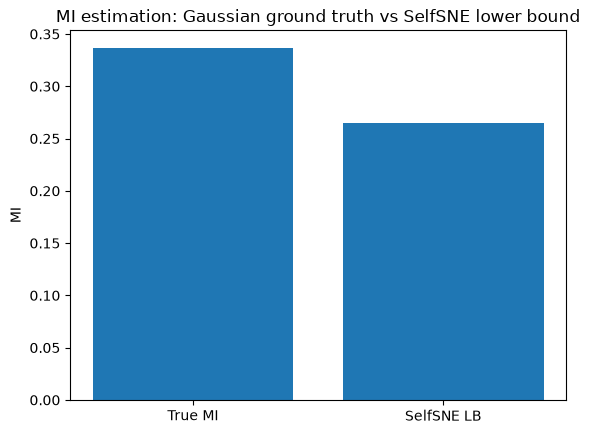

In [9]:
import matplotlib
import matplotlib.pyplot as plt
plt.figure()
plt.bar(["True MI", "SelfSNE LB"], [true_mi, mi_lb_g])
plt.ylabel("MI")
plt.title("MI estimation: Gaussian ground truth vs SelfSNE lower bound")
plt.show()

## MI estimation with increasing known MI

Keep the latent variables fixed and re-target `y` each step as
`y = rho*x + sqrt(1 - rho^2)*eps`, with `rho` following a staircase. The bivariate
`(x, y)` is a Gaussian with correlation `rho`, so the true MI at every step is the
analytic `I(rho) = -0.5 log(1 - rho^2)`. We train ONE DV/MINE model (`kld` +
`batch` baseline, Cauchy kernel) through the whole ramp -- the data distribution
changes non-stationarily as the MI climbs -- and sample the bound
`E_pos[f] - log E_neg[e^f]` at the end of each level. The estimator's trajectory
is then compared against the staircase of known MI.


In [10]:
import torch
from selfsne import SelfSNE, get_lr_scheduler
from selfsne.losses import LikelihoodRatioEstimator
from selfsne.nn.norm import InputNorm1d

torch.manual_seed(1)
N, batch = 4000, 512
# Fixed latent variables: independent x and noise eps. The target is made to
# correlate with x by rho, so (x, y) is a bivariate Gaussian with known MI.
x_lat = torch.randn(N, 1)
eps = torch.randn(N, 1)

def make_target(xb, eb, rho):
    return rho * xb + (1.0 - rho * rho) ** 0.5 * eb

# Staircase of known correlation -> true MI = -0.5 log(1 - rho^2), monotonically up.
rho_levels = torch.linspace(0.2, 0.9, 8)
true_mi_levels = -0.5 * torch.log(1.0 - rho_levels ** 2)

encoder = torch.nn.Sequential(
    InputNorm1d(1),
    torch.nn.Linear(1, 128),
    torch.nn.SELU(),
    torch.nn.Linear(128, 64),
    torch.nn.SELU(),
    torch.nn.Linear(64, 2),
)
model_r = SelfSNE(loss=LikelihoodRatioEstimator(divergence="kld", baseline="batch"), target_encoder=encoder)
opt = torch.optim.AdamW(model_r.parameters(), lr=0.003, betas=(0.9, 0.999))
steps_per_level = 200
total_steps = steps_per_level * len(rho_levels)
sched = get_lr_scheduler(opt, warmup_steps=80, target_steps=0, cosine_steps=total_steps - 80)

def estimate_bound(model, rho):
    # DV/MINE lower bound:  I >= E_pos[f] - log E_neg[e^f]
    model.eval()
    pos, negexp = [], []
    with torch.no_grad():
        for i in range(0, N, batch):
            xb, eb = x_lat[i:i + batch], eps[i:i + batch]
            yb = make_target(xb, eb, rho)
            ctx, tgt, _, _ = model.get_embeddings(xb, yb, None)
            lg = model.loss.logits(ctx, tgt)
            pos.append(lg["pos_logits"].mean())
            negexp.append(torch.exp(lg["neg_logits"]).mean())
    return (torch.stack(pos).mean() - torch.stack(negexp).mean().log()).item()

step = 0
record = []
for lvl, rho in enumerate(rho_levels):
    rho_f = float(rho)
    for _ in range(steps_per_level):
        idx = torch.randint(0, N, (batch,))
        xb, eb = x_lat[idx], eps[idx]
        yb = make_target(xb, eb, rho_f)
        model_r.train()
        opt.zero_grad()
        ctx, tgt, _, _ = model_r.get_embeddings(xb, yb, None)
        loss = model_r.loss(context_embedding=ctx, target_embedding=tgt)["loss"]
        loss.backward()
        opt.step()
        sched.step()
        step += 1
    bound = estimate_bound(model_r, rho_f)
    record.append((step, rho_f, float(true_mi_levels[lvl]), bound))
    print(f"step {step:5d}  rho={rho_f:.2f}  true MI={true_mi_levels[lvl]:.3f}  bound={bound:.3f}")


step   200  rho=0.20  true MI=0.020  bound=0.015


step   400  rho=0.30  true MI=0.047  bound=0.035


step   600  rho=0.40  true MI=0.087  bound=0.066


step   800  rho=0.50  true MI=0.144  bound=0.110


step  1000  rho=0.60  true MI=0.223  bound=0.172


step  1200  rho=0.70  true MI=0.337  bound=0.264


step  1400  rho=0.80  true MI=0.511  bound=0.410


step  1600  rho=0.90  true MI=0.830  bound=0.685


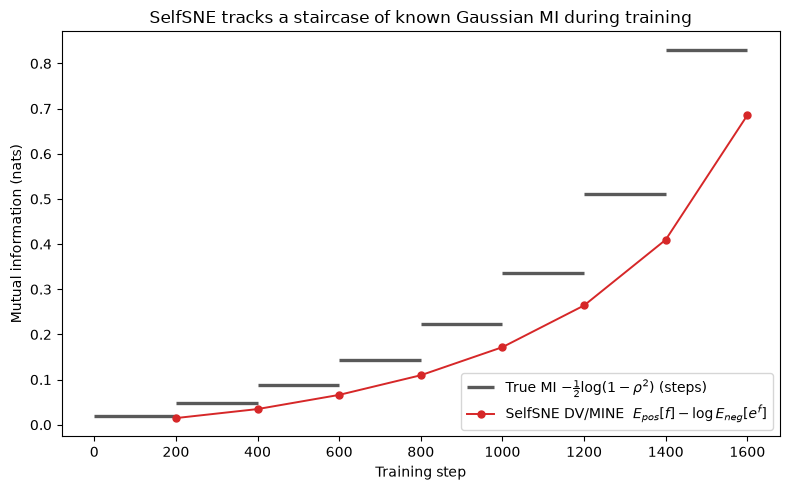

In [11]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np

steps = np.array([r[0] for r in record])
rhos = np.array([r[1] for r in record])
true_mi = np.array([r[2] for r in record])
bounds = np.array([r[3] for r in record])

fig, ax = plt.subplots(figsize=(8, 5))
# true-MI staircase: each known level holds constant over its training block
for i in range(len(true_mi)):
    ax.hlines(true_mi[i], i * steps_per_level, (i + 1) * steps_per_level,
              color="0.35", lw=2.4,
              label="True MI $-\\frac{1}{2}\\log(1-\\rho^2)$ (steps)" if i == 0 else None)
ax.plot(steps, bounds, "o-", color="tab:red", ms=5, lw=1.4,
        label="SelfSNE DV/MINE  $E_{pos}[f]-\\log E_{neg}[e^{f}]$")
ax.set_xlabel("Training step")
ax.set_ylabel("Mutual information (nats)")
ax.set_title("SelfSNE tracks a staircase of known Gaussian MI during training")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()


## 2D embedding of a simple dataset (Cauchy kernel)

A minimal self-supervised embedding on a simple dataset: 400 points on a closed
4D curve `(sin t, cos t, sin 2t, cos 2t)`. Each point is paired with its neighbour
along the loop (consecutive `t`). We train a 2D encoder with the **Cauchy kernel**
(the default) and the `kld` + `batch` objective, which pulls paired (neighbour)
points together and pushes unpaired ones apart. The 2D embedding is plotted below,
colored by the driving angle `t`, to show the loop structure the model recovered.
A quantitative check confirms neighbours along `t` land much closer in the embedding
than random pairs.


In [12]:
import torch
from selfsne import SelfSNE
from selfsne.losses import LikelihoodRatioEstimator
from selfsne.nn.norm import InputNorm1d

pl.seed_everything(0)
Nring, batch_ring = 400, 100
t = torch.arange(Nring, dtype=torch.float32) * (2 * torch.pi / Nring)
X = torch.stack([torch.sin(t), torch.cos(t), torch.sin(2 * t), torch.cos(2 * t)], dim=1)
# self-supervised pairing: each point pairs with its neighbour along the loop
ring_ds = TensorDataset(X, torch.roll(X, shifts=-1, dims=0))
ring_loader = DataLoader(ring_ds, batch_size=batch_ring, shuffle=True)

encoder_ring = torch.nn.Sequential(
    InputNorm1d(4),
    torch.nn.Linear(4, 64),
    torch.nn.SELU(),
    torch.nn.Linear(64, 32),
    torch.nn.SELU(),
    torch.nn.Linear(32, 2),
)
model_e = SelfSNE(
    loss=LikelihoodRatioEstimator(kernel="cauchy", divergence="kld", baseline="batch"),
    target_encoder=encoder_ring,
    learning_rate=0.003,
    lr_scheduler=True,
    lr_warmup_steps=80,
    lr_target_steps=0,
    lr_cosine_steps=1400,
)
trainer_e = pl.Trainer(max_epochs=400, accelerator="cpu", devices=1, logger=False,
                       enable_checkpointing=False, enable_progress_bar=False)
trainer_e.fit(model_e, ring_loader)


Seed set to 0


GPU available: True (cuda), used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


┏━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name             ┃ Type                     ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ loss             │ LikelihoodRatioEstimator │      0 │ train │     0 │
│ 1 │ target_encoder   │ Sequential               │  2.5 K │ train │     0 │
│ 2 │ target_tokenizer │ Identity                 │      0 │ train │     0 │
└───┴──────────────────┴──────────────────────────┴────────┴───────┴───────┘

Trainable params: 2.5 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 2.5 K                                                                                                
Total estimated model params size (MB): 0.010                                                                      
Modules in train mode: 10                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

`Trainer.fit` stopped: `max_epochs=400` reached.


2D embedding shape: (400, 2)
mean neighbour-embedding distance = 1.4936,  random = 65.4355


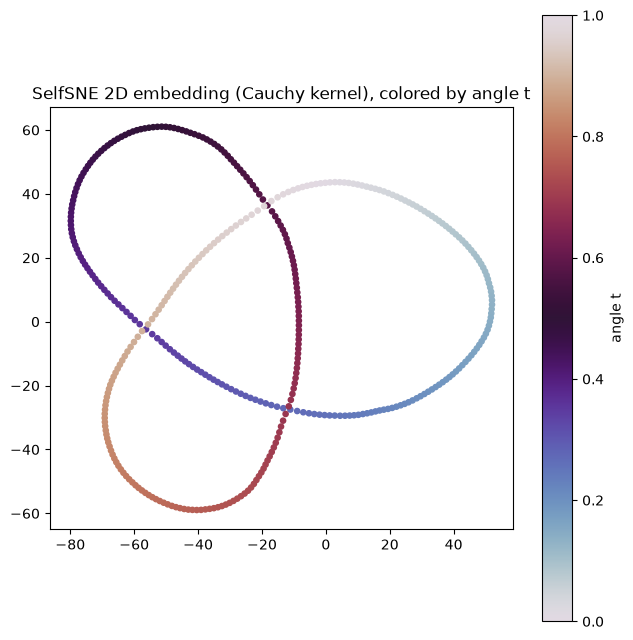

In [13]:
import numpy as np
model_e.eval()
with torch.no_grad():
    emb, _, _, _ = model_e.get_embeddings(X, X, None)
    emb = emb.numpy()
print("2D embedding shape:", emb.shape)

# quantitative check: neighbours along the loop (t) should sit much closer than random pairs
d_neigh = np.linalg.norm(np.roll(emb, -1, axis=0) - emb, axis=1).mean()
rng = np.random.default_rng(0)
ii, jj = rng.integers(0, emb.shape[0], size=4000), rng.integers(0, emb.shape[0], size=4000)
d_rand = np.linalg.norm(emb[ii] - emb[jj], axis=1).mean()
print(f"mean neighbour-embedding distance = {d_neigh:.4f},  random = {d_rand:.4f}")

import matplotlib
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6.5, 6.5))
sc = ax.scatter(emb[:, 0], emb[:, 1], c=t.numpy() / (2 * np.pi), cmap="twilight",
                s=14, vmin=0, vmax=1)
ax.set_aspect("equal")
ax.set_title("SelfSNE 2D embedding (Cauchy kernel), colored by angle t")
fig.colorbar(sc, ax=ax, label="angle t")
fig.tight_layout()
plt.show()
